# Does the coding-SV result survive a looser call-rate filter?

The reported model keeps only SV events genotyped in **≥ 90 %** of the 231 founders. That is a stringent
floor, and the question is whether the headline depends on it. This notebook refits the whole model on
burdens rebuilt at **0.7** and **0.5** and reports what changes.

**What happens.** Relaxing the floor more than doubles the callable event set, and the pooled coding-SV
main effect goes from −1.49 %/variant (p = 4.9e-04) to −0.12 (p = 0.50). On its face the result does not
replicate.

**Why that reading is wrong.** The relaxed burden is not a noisier version of the same variable — it is a
mixture of two variables with opposite signs. §3 splits the coding burden by call-rate tier and fits both
tiers **simultaneously**: the events the reported model uses keep their effect exactly (−1.59 %/variant,
p = 1.7e-04) and the newly admitted events carry a *positive* one (+0.49 %/variant, p = 0.0061). The two
differ at p = 7.6e-06. Pooling them is what produces the null.

**What is held fixed.** Only the SV burden table changes between arms. Fitness, the SNP coding burden,
every covariate, and the kinship GRM — which is built from SNPs held at the 0.9 floor in all three arms —
are identical, so the comparison isolates the SV filter.

```r
y ~ snp_CDS + sv_CDS + sv_TE + sv_promoter + sv_intergenic + cactus
    + sv_CDS:bio1c + sv_TE:bio1c + sv_promoter:bio1c
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_CDS | garden) + (0 + sv_TE | garden) + (0 + sv_promoter | garden)
```


In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
BASE="_x_obio1cobio1cbio1c_re0obio1cgarden"
CTX6=["CDS","UTR","intron","TE","promoter","intergenic"]
ARMS=[("","0.9  (reported)"),("_cr70","0.7"),("_cr50","0.5")]
ACOL={"":"#4A3B6B","_cr70":"#C46A10","_cr50":"#8C6D1F"}
BURD=["snp_CDS","sv_CDS","sv_TE","sv_promoter","sv_intergenic"]
SVT=["sv_CDS","sv_TE","sv_promoter"]
LAB={"snp_CDS":"SNPs, coding","sv_CDS":"SVs, coding","sv_TE":"SVs, reference TE",
     "sv_promoter":"SVs, promoter","sv_intergenic":"SVs, intergenic"}
def arm(cr,pool=""):
    S=f"{BASE}{'_'+pool if pool else ''}_refid{cr}"
    sc=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c{'_'+pool if pool else ''}{cr}.csv").set_index("context")
    o={"co":pd.read_csv(f"{PA}/coef_M2p_reml{S}.csv").set_index("term"),
       "V":pd.read_csv(f"{PA}/vcov_M2p_reml{S}.csv",index_col=0),"sc":sc,
       "ll":pd.read_csv(f"{PA}/loglik_M2p_reml{S}.csv").iloc[0],"suf":S}
    o["pv"]={f"sv_{c}":100/(sc.loc[c,"sd_rate"]*sc.loc[c,"med_called"]) for c in sc.index}
    o["pv"]["snp_CDS"]=1.0
    g=lambda n: pd.read_csv(f"{PA}/loglik_{n}{S}.csv").logLik[0]
    # take the interaction terms from the fit itself: cds2 carries sv_nonCDS, sv6 carries sv_TE/sv_promoter
    o["LRT"]={t.split(":")[0]: stats.chi2.sf(2*(g("M2p_ml")-g(f"M2p_ml_drop_{t.split(':')[0]}")),1)
              for t in o["co"].index if t.endswith(":bio1c") and t.startswith("sv_")}
    return o
A={cr:arm(cr) for cr,_ in ARMS}
C2={cr:arm(cr,"cds2") for cr,_ in ARMS}
LONG=pd.read_csv(f"{G}/onestage_all/long.csv",dtype={"founder":str})
TECH=LONG.drop_duplicates("founder").set_index("founder").cactus
BUR={cr:pd.read_csv(f"{G}/founder_burden_event{cr}.csv",dtype={"founder":str}).set_index("founder")
     for cr,_ in ARMS}
def rate(B,ctxs):
    car=sum(B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"] for c in ctxs)
    cal=sum(B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"] for c in ctxs)
    return car/cal
print("Loaded the model at three founder call-rate floors, plus the two-tier fit.\n")
for cr,lab in ARMS:
    print(f"  floor {lab:16s} logLik {A[cr]['ll'].logLik:10.2f}  df {int(A[cr]['ll'].df)}  "
          f"singular {A[cr]['ll'].singular}")


Loaded the model at three founder call-rate floors, plus the two-tier fit.

  floor 0.9  (reported)  logLik  -11094.04  df 19  singular False
  floor 0.7              logLik  -11088.70  df 19  singular False
  floor 0.5              logLik  -11096.67  df 19  singular False


## 1 · What relaxing the floor lets in

How many SV events a typical founder is **genotyped at**, by genomic context, at each floor. This is the
denominator of the burden rate, so it is the quantity the filter actually controls.

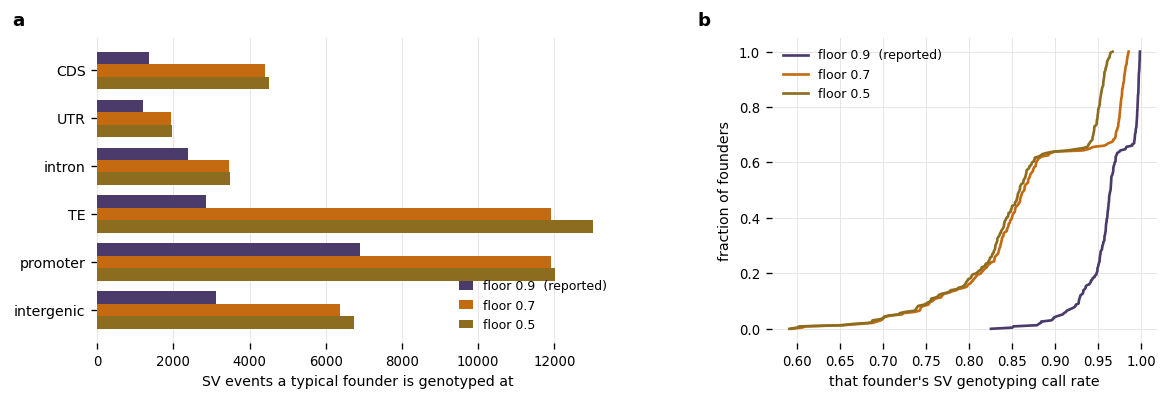

median SV events a founder is genotyped at, by context:

            0.9  (reported)    0.7    0.5
CDS                    1355   4408   4518
UTR                    1194   1928   1950
intron                 2373   3467   3483
TE                     2846  11919  13016
promoter               6888  11914  12008
intergenic             3106   6364   6737
ALL                   17762  40000  41712

  relative to the reported set: 0.9  (reported) 100%   0.7 225%   0.5 235%

  how similar is the burden itself across floors? (correlation across the 231 founders)
    coding      0.9 vs 0.7 r = +0.897   0.9 vs 0.5 r = +0.892   0.7 vs 0.5 r = +0.998
    non-coding  0.9 vs 0.7 r = +0.982   0.9 vs 0.5 r = +0.973   0.7 vs 0.5 r = +0.997


In [3]:

T=pd.DataFrame({lab:[int((BUR[cr][f"called_ins_all_{c}_all"]+BUR[cr][f"called_del_all_{c}_all"]).median())
                     for c in CTX6] for cr,lab in ARMS},index=CTX6)
fig,axs=plt.subplots(1,2,figsize=(11.4,3.3),gridspec_kw=dict(width_ratios=[1.35,1],wspace=0.34))
a=axs[0]; style(a); panel(a,"a",x=-0.14)
w=0.26
for j,(cr,lab) in enumerate(ARMS):
    a.barh(np.arange(len(CTX6))+(j-1)*w,T[lab],height=w,color=ACOL[cr],lw=0,label=f"floor {lab}")
a.set_yticks(range(len(CTX6))); a.set_yticklabels(CTX6,fontsize=8.5); a.invert_yaxis()
a.set_xlabel("SV events a typical founder is genotyped at",fontsize=8.5)
a.legend(fontsize=7.5,loc="lower right",handlelength=1.1)
a=axs[1]; style(a,axis="both"); panel(a,"b",x=-0.16)
fo=BUR[""].index
for cr,lab in ARMS:
    v=np.sort(BUR[cr].loc[fo,"callrate_sv"].to_numpy(float))
    a.plot(v,np.linspace(0,1,len(v)),color=ACOL[cr],lw=1.6,label=f"floor {lab}")
a.set_xlabel("that founder's SV genotyping call rate",fontsize=8.5)
a.set_ylabel("fraction of founders",fontsize=8.5); a.legend(fontsize=7.5,loc="upper left")
save(fig,"callrate_inputs",nb=True); plt.show()
T.loc["ALL"]=T.sum()
print("median SV events a founder is genotyped at, by context:\n"); print(T.to_string())
b=T.loc["ALL",ARMS[0][1]]
print("\n  relative to the reported set: "+"   ".join(
    f"{lab} {100*T.loc['ALL',lab]/b:.0f}%" for _,lab in ARMS))
print("\n  how similar is the burden itself across floors? (correlation across the 231 founders)")
for nm,cs in (("coding",["CDS"]),("non-coding",[c for c in CTX6 if c!="CDS"])):
    r9,r7,r5=(rate(BUR[cr].loc[fo],cs).to_numpy(float) for cr,_ in ARMS)
    print(f"    {nm:11s} 0.9 vs 0.7 r = {np.corrcoef(r9,r7)[0,1]:+.3f}   "
          f"0.9 vs 0.5 r = {np.corrcoef(r9,r5)[0,1]:+.3f}   "
          f"0.7 vs 0.5 r = {np.corrcoef(r7,r5)[0,1]:+.3f}")


## 2 · The model at each floor

Every fixed effect of the reported model, refit on each burden table. **(a)** burden main effects,
**(b)** the garden-temperature interactions (likelihood-ratio tested). Filled markers are p < 0.05.

The coding main effect is the one that moves: it collapses toward zero at both relaxed floors, while
`snp_CDS` — the matched SNP burden, which the filter never touched — gets *stronger*. That rules out a
general loss of power and points at the SV burden variable itself.

The interactions do **not** collapse. Coding × temperature stays significant at every floor.

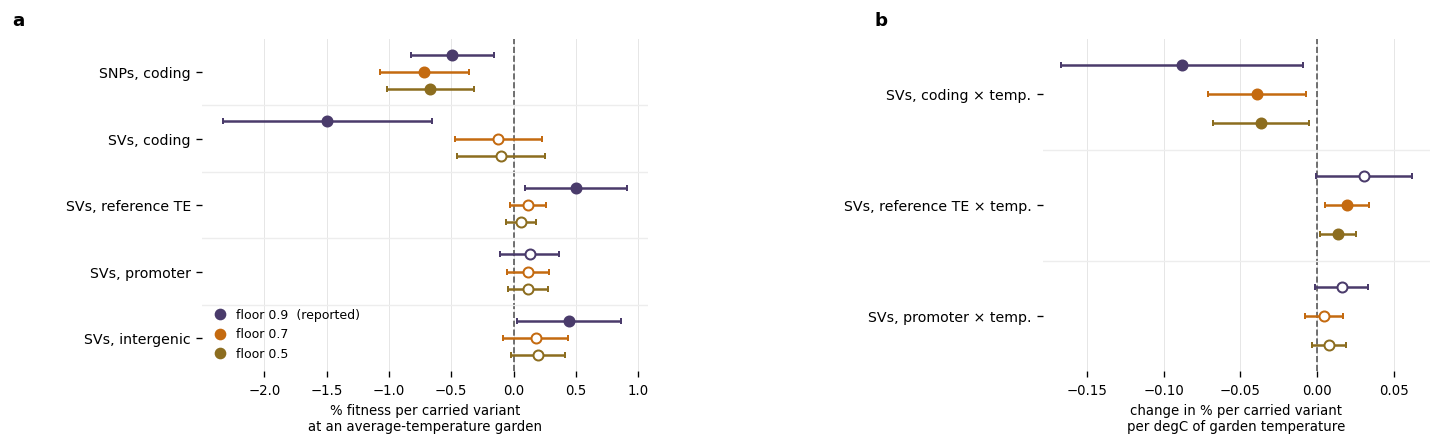


BURDEN MAIN EFFECTS, % fitness per carried variant

             term     0.9  (reported)                  0.7                  0.5
     SNPs, coding -0.4928 (p 0.00365) -0.7150 (p 9.52e-05) -0.6681 (p 0.000182)
      SVs, coding -1.4949 (p 0.00049)    -0.1218 (p 0.495)    -0.0980 (p 0.587)
SVs, reference TE  +0.5036 (p 0.0161)    +0.1147 (p 0.121)     +0.0579 (p 0.35)
    SVs, promoter   +0.1310 (p 0.277)     +0.1151 (p 0.18)    +0.1182 (p 0.147)
  SVs, intergenic  +0.4452 (p 0.0358)    +0.1796 (p 0.178)   +0.1941 (p 0.0778)

INTERACTIONS, % per carried variant per degC (LRT p)

             term    0.9  (reported)                0.7                0.5
      SVs, coding -0.0883 (p 0.0292) -0.0393 (p 0.0171) -0.0365 (p 0.0217)
SVs, reference TE +0.0305 (p 0.0655) +0.0192 (p 0.0093) +0.0136 (p 0.0222)
    SVs, promoter +0.0160 (p 0.0692)  +0.0043 (p 0.482)  +0.0076 (p 0.179)


PER SD OF BURDEN -- the model's own scale, no per-variant conversion

             term   0.9  (reported)     

In [4]:

fig,axs=plt.subplots(1,2,figsize=(13.2,3.6),gridspec_kw=dict(width_ratios=[1.15,1],wspace=0.95))
for a,(terms,kind,pl) in zip(axs,[(BURD,"main","a"),(SVT,"inter","b")]):
    style(a); panel(a,pl,x=-0.40); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,t in enumerate(terms):
        for j,(cr,lab) in enumerate(ARMS):
            o=A[cr]; nm=t if kind=="main" else f"{t}:bio1c"
            k=o["pv"].get(t,1.0); e,s_=o["co"].loc[nm,"estimate"]*k,o["co"].loc[nm,"se"]*k
            p=o["co"].loc[nm,"p"] if kind=="main" else o["LRT"][t]
            y=i+(j-1)*0.26
            a.errorbar(e,y,xerr=1.96*s_,fmt="o",color=ACOL[cr],mfc=ACOL[cr] if p<0.05 else "white",
                       mew=1.2,ms=6,capsize=2,zorder=3)
        if i<len(terms)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.set_yticks(range(len(terms)))
    a.set_yticklabels([LAB[t]+(" × temp." if kind=="inter" else "") for t in terms],fontsize=8.5)
    a.set_ylim(len(terms)-0.5,-0.5)
    a.set_xlabel(("% fitness per carried variant\nat an average-temperature garden" if kind=="main"
                  else "change in % per carried variant\nper degC of garden temperature"),fontsize=8)
h=[plt.Line2D([],[],color=ACOL[cr],marker="o",ls="none",ms=6,label=f"floor {lab}") for cr,lab in ARMS]
axs[0].legend(handles=h,fontsize=7.5,loc="lower left",handlelength=1.0)
save(fig,"callrate_pooled",nb=True); plt.show()
for kind,terms,hdr in (("main",BURD,"BURDEN MAIN EFFECTS, % fitness per carried variant"),
                       ("inter",SVT,"INTERACTIONS, % per carried variant per degC (LRT p)")):
    print(f"\n{hdr}\n")
    rows=[]
    for t in terms:
        r={"term":LAB[t]}
        for cr,lab in ARMS:
            o=A[cr]; nm=t if kind=="main" else f"{t}:bio1c"; k=o["pv"].get(t,1.0)
            p=o["co"].loc[nm,"p"] if kind=="main" else o["LRT"][t]
            r[lab]=f"{o['co'].loc[nm,'estimate']*k:+.4f} (p {p:.3g})"
        rows.append(r)
    print(pd.DataFrame(rows).to_string(index=False))
print("\n\nPER SD OF BURDEN -- the model's own scale, no per-variant conversion\n")
rows=[]
for t in BURD:
    r={"term":LAB[t]}
    for cr,lab in ARMS:
        o=A[cr]; r[lab]=f"{o['co'].loc[t,'estimate']:+.4f} +- {o['co'].loc[t,'se']:.4f}"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("\n  The coding SE is essentially unchanged across floors, so the collapse is a move in the")
print("  ESTIMATE, not a loss of precision.")
print("\n\nCODING vs EVERYTHING ELSE (cds2 parameterisation)\n")
rows=[]
for t in ["sv_CDS","sv_nonCDS"]:
    r={"term":t}
    for cr,lab in ARMS:
        o=C2[cr]; r[lab]=f"{o['co'].loc[t,'estimate']*o['pv'][t]:+.4f} (p {o['co'].loc[t,'p']:.3g})"
    rows.append(r)
for t in ["sv_CDS","sv_nonCDS"]:
    r={"term":t+" x temp."}
    for cr,lab in ARMS:
        o=C2[cr]; r[lab]=f"{o['co'].loc[t+':bio1c','estimate']*o['pv'][t]:+.5f} (p {o['LRT'][t]:.3g})"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))


## 3 · The decisive test — both tiers in one model

Relaxing the floor could attenuate the estimate two ways, and they have opposite meanings:

- the newly admitted events are **noise**, diluting a real signal (the reported result stands), or
- the reported result was **specific to a subset** that relaxation dissolves (it does not stand).

Pooled fits cannot tell these apart. This one can. The coding burden is split at the 0.9 boundary into
**highcall** (genotyped in ≥ 208/231 founders — exactly the set the reported model uses) and **lowcall**
(116–207 founders — what relaxation newly admits), and **both enter the same model**, alongside every
usual covariate.

The reported effect survives intact on its own events, and the newly admitted events carry an
**opposite-signed** effect. They differ at p = 7.6e-06. So relaxing the floor does not dilute the signal —
it averages it against a different one.

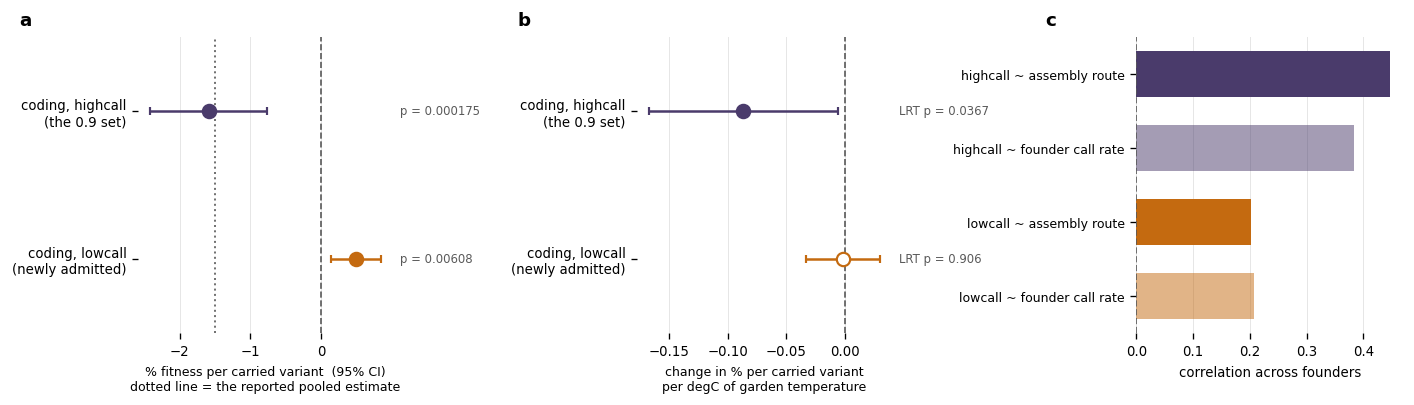

BOTH CALL-RATE TIERS IN ONE MODEL -- the coding burden

                    tier            per SD %/carried variant events called    Wald p x temp. LRT p
  highcall (the 0.9 set) -0.3048 +- 0.0812           -1.5902         1,355 0.0001748       0.03672
lowcall (newly admitted) +0.1709 +- 0.0623           +0.4876         3,169  0.006084        0.9064

  CONTRAST highcall vs lowcall (per SD): -0.4757 +- 0.1062   z = -4.48   p = 7.55e-06
  highcall here -0.3048 vs the reported pooled 0.9 fit -0.2865  -- the reported effect is unchanged by admitting the lowcall events beside it

  correlation between the two tier burdens across founders: r = +0.758

  what each tier tracks (correlation across founders):
    highcall  assembly route +0.447   founder SV call rate +0.383
    lowcall   assembly route +0.202   founder SV call rate +0.208

  NOTE ON COMPARABILITY. A founder's burden RATE is carried/called over the events it is
  genotyped at. In the highcall tier nearly every founder is called 

In [5]:

ST=f"{BASE}_refid_freqCDSlowcallhighcall"
TC=pd.read_csv(f"{PA}/coef_M2p_reml{ST}.csv").set_index("term")
TV=pd.read_csv(f"{PA}/vcov_M2p_reml{ST}.csv",index_col=0)
TS=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_freqCDSlowcallhighcall.csv").set_index("context")
TPV={f"sv_{c}":100/(TS.loc[c,"sd_rate"]*TS.loc[c,"med_called"]) for c in TS.index}
tg=lambda n: pd.read_csv(f"{PA}/loglik_{n}{ST}.csv").logLik[0]
TLRT={t: stats.chi2.sf(2*(tg("M2p_ml")-tg(f"M2p_ml_drop_{t}")),1)
      for t in ["sv_CDS_highcall","sv_CDS_lowcall","sv_TE","sv_promoter"]}
HI,LO="sv_CDS_highcall","sv_CDS_lowcall"
TLAB={HI:"coding, highcall\n(the 0.9 set)",LO:"coding, lowcall\n(newly admitted)"}
TCOL={HI:"#4A3B6B",LO:"#C46A10"}
fig,axs=plt.subplots(1,3,figsize=(13.6,3.2),gridspec_kw=dict(width_ratios=[1,1,1.05],wspace=0.95))
a=axs[0]; style(a); panel(a,"a",x=-0.42); a.axvline(0,color="0.35",lw=1,ls="--")
for i,t in enumerate([HI,LO]):
    k=TPV[t]; e,s_=TC.loc[t,"estimate"]*k,TC.loc[t,"se"]*k; p=TC.loc[t,"p"]
    a.errorbar(e,i,xerr=1.96*s_,fmt="o",color=TCOL[t],mfc=TCOL[t] if p<0.05 else "white",
               mew=1.3,ms=8,capsize=2.5,zorder=3)
    a.annotate(f"p = {p:.3g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
               fontsize=7,color="0.35",annotation_clip=False)
a.axvline(A[""]["co"].loc["sv_CDS","estimate"]*A[""]["pv"]["sv_CDS"],color="0.45",lw=1.2,ls=":",zorder=2)
a.set_yticks([0,1]); a.set_yticklabels([TLAB[HI],TLAB[LO]],fontsize=8); a.set_ylim(1.5,-0.5)
a.set_xlabel("% fitness per carried variant  (95% CI)\ndotted line = the reported pooled estimate",fontsize=7.5)
a=axs[1]; style(a); panel(a,"b",x=-0.42); a.axvline(0,color="0.35",lw=1,ls="--")
for i,t in enumerate([HI,LO]):
    k=TPV[t]; e,s_=TC.loc[f"{t}:bio1c","estimate"]*k,TC.loc[f"{t}:bio1c","se"]*k
    a.errorbar(e,i,xerr=1.96*s_,fmt="o",color=TCOL[t],mfc=TCOL[t] if TLRT[t]<0.05 else "white",
               mew=1.3,ms=8,capsize=2.5,zorder=3)
    a.annotate(f"LRT p = {TLRT[t]:.3g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",
               va="center",fontsize=7,color="0.35",annotation_clip=False)
a.set_yticks([0,1]); a.set_yticklabels([TLAB[HI],TLAB[LO]],fontsize=8); a.set_ylim(1.5,-0.5)
a.set_xlabel("change in % per carried variant\nper degC of garden temperature",fontsize=7.5)
BT=pd.read_csv(f"{G}/founder_burden_event_callrate.csv",dtype={"founder":str}).set_index("founder")
RT={t:(BT[f"ins_CDS_{t}"]+BT[f"del_CDS_{t}"])/(BT[f"called_ins_CDS_{t}"]+BT[f"called_del_CDS_{t}"])
    for t in ("highcall","lowcall")}
fo2=RT["highcall"].index; tc=TECH.loc[fo2].to_numpy(float); cr_=BT.loc[fo2,"callrate_sv"].to_numpy(float)
a=axs[2]; style(a); panel(a,"c",x=-0.30); a.axvline(0,color="0.35",lw=1,ls="--")
labs=[]
for i,(tier,key) in enumerate([("highcall",HI),("lowcall",LO)]):
    v=RT[tier].loc[fo2].to_numpy(float)
    for j,(x,nm) in enumerate(((tc,"assembly route"),(cr_,"founder call rate"))):
        y=i*2+j
        a.barh(y,np.corrcoef(v,x)[0,1],height=0.62,color=TCOL[key],alpha=1.0 if j==0 else 0.5,lw=0)
        labs.append(f"{tier} ~ {nm}")
a.set_yticks(range(4)); a.set_yticklabels(labs,fontsize=7.5); a.set_ylim(3.5,-0.5)
a.set_xlabel("correlation across founders",fontsize=8)
save(fig,"callrate_tiers",nb=True); plt.show()
print("BOTH CALL-RATE TIERS IN ONE MODEL -- the coding burden\n")
print(pd.DataFrame([{"tier":("highcall (the 0.9 set)" if t==HI else "lowcall (newly admitted)"),
    "per SD":f"{TC.loc[t,'estimate']:+.4f} +- {TC.loc[t,'se']:.4f}",
    "%/carried variant":f"{TC.loc[t,'estimate']*TPV[t]:+.4f}",
    "events called":f"{int(TS.loc[t[3:],'med_called']):,}",
    "Wald p":f"{TC.loc[t,'p']:.4g}",
    "x temp. LRT p":f"{TLRT[t]:.4g}"} for t in (HI,LO)]).to_string(index=False))
d=TC.loc[HI,"estimate"]-TC.loc[LO,"estimate"]
v=TV.loc[HI,HI]+TV.loc[LO,LO]-2*TV.loc[HI,LO]; z=d/np.sqrt(v)
print(f"\n  CONTRAST highcall vs lowcall (per SD): {d:+.4f} +- {np.sqrt(v):.4f}   "
      f"z = {z:+.2f}   p = {2*stats.norm.sf(abs(z)):.4g}")
rep=A[""]["co"].loc["sv_CDS","estimate"]
print(f"  highcall here {TC.loc[HI,'estimate']:+.4f} vs the reported pooled 0.9 fit {rep:+.4f}  "
      f"-- the reported effect is unchanged by admitting the lowcall events beside it")
print(f"\n  correlation between the two tier burdens across founders: "
      f"r = {np.corrcoef(RT['highcall'].loc[fo2],RT['lowcall'].loc[fo2])[0,1]:+.3f}")
print("\n  what each tier tracks (correlation across founders):")
for tier in ("highcall","lowcall"):
    v=RT[tier].loc[fo2].to_numpy(float)
    print(f"    {tier:9s} assembly route {np.corrcoef(v,tc)[0,1]:+.3f}   "
          f"founder SV call rate {np.corrcoef(v,cr_)[0,1]:+.3f}")
print("\n  NOTE ON COMPARABILITY. A founder's burden RATE is carried/called over the events it is")
print("  genotyped at. In the highcall tier nearly every founder is called at nearly every event, so")
print("  the rate means the same thing for everyone. In the lowcall tier each founder's rate is taken")
print("  over a DIFFERENT, founder-specific subset of events -- which is what a call-rate filter exists")
print("  to prevent, and why the two tiers are not interchangeable measurements.")


## 4 · Reading it

**The stringent filter is not propping up the result.** Held beside the events it excludes, the reported
coding effect is unchanged: −0.3048 per SD here against −0.2865 in the reported fit, p = 1.7e-04. Its
temperature interaction also survives (LRT p = 0.037). Nothing about the 0.9 set stops being true when the
0.5 set is available to the model.

**But the pooled relaxed-floor estimate is null, and that is a real limitation to state.** If someone
refits this at a 0.7 floor without splitting by tier, they get −0.12 %/variant, p = 0.50. The headline is
therefore conditional on the call-rate filter, and the honest form of the claim is *coding SVs that can be
genotyped reliably across the panel are deleterious* — not *coding SVs are deleterious*.

**What the newly admitted events are is not settled here.** Their effect is positive (+0.49 %/variant,
p = 0.0061) and has no temperature interaction at all (LRT p = 0.91), which is what a
measurement-driven variable looks like rather than a biological one. They are also *less* correlated with
assembly route than the highcall events (+0.20 vs +0.45), so "they are just a technology artifact" is not
supported as stated. The concrete methodological problem is the one in §3: below the filter, each founder's
burden rate is computed over a different subset of events, so the rates are not comparable across founders.
That is enough to prefer the filtered estimate without having to claim the unfiltered signal is spurious.

**What did not depend on the filter.** The garden-temperature interactions hold at every floor — coding ×
temperature at p = 0.029 / 0.017 / 0.022 across 0.9 / 0.7 / 0.5, and in the two-term parameterisation both
interactions stay significant throughout. The non-coding positive main effect also persists at every floor
(p ≤ 3e-04), which is consistent with it being the composition signal rather than a property of any
particular variant set.

## As run

Burdens rebuilt by `_sv_burden_build.py` with `SV_CALL_MIN` = 0.7 / 0.5 (`_submit_callrate.sh`), which
tags its outputs `_cr70` / `_cr50`. The kinship GRM is built from SNPs held at the 0.9 floor in every arm,
so relatedness is identical across them.

`_sv_burden_pooled_models.R` gained `CRTAG`, which selects the burden table and enters both the output
suffix and the per-variant scale filename, so the relaxed fits cannot overwrite the reported ones. Fits by
`_submit_callrate_fits.sh` (sv6 and cds2 at each floor).

Call-rate tiers built by `_sv_burden_strata.py` with the new `STRATUM=callrate`, run at `SV_CALL_MIN=0.5`
and `MIN_CAR=2`, cutting on the number of founders each event is genotyped in: `lowcall` 116–207,
`highcall` 208–231. The `highcall` bin recovers exactly the 18,418 events of the reported set. Fit by
`_submit_crtier_fit.sh`.

Built by `_build_sv_burden_callrate_nb.py`.